# Exercise No 11: Machine Learning Classification using PySpark
### Algorithms: Logistic Regression, Support Vector Machine (LinearSVC), Decision Tree Classifier
### Evaluation: Accuracy, Precision, Recall, F1-Measure & Performance Comparison Graphs

## 1. Setup Environment & Initialize SparkSession
We configure `JAVA_HOME` pointing to OpenJDK 17 and initialize a local `SparkSession`.

In [ ]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, LinearSVC, DecisionTreeClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from sklearn.metrics import confusion_matrix, classification_report

spark = SparkSession.builder \
    .appName("Ex11_PySpark_Classification") \
    .master("local[*]") \
    .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")
print(f"Spark Version: {spark.version}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/ghua/bda/.venv/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/08/18 22:34:18 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/08/18 22:34:18 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Spark Version: 4.2.0


## 2. Load and Explore the Classification Dataset

In [2]:
df = spark.read.csv("dataset.csv", header=True, inferSchema=True)
print(f"Dataset Shape: ({df.count()}, {len(df.columns)})")
df.show(5)

Dataset Shape: (235, 14)
+---+---+---+--------+----+---+-------+-------+-----+-------+-----+---+----+------+
|age|sex| cp|trestbps|chol|fbs|restecg|thalach|exang|oldpeak|slope| ca|thal|target|
+---+---+---+--------+----+---+-------+-------+-----+-------+-----+---+----+------+
| 63|  1|  3|     145| 233|  1|      0|    150|    0|    2.3|    0|  0|   1|     1|
| 37|  1|  2|     130| 250|  0|      1|    187|    0|    3.5|    0|  0|   2|     1|
| 41|  0|  1|     130| 204|  0|      0|    172|    0|    1.4|    2|  0|   2|     1|
| 56|  1|  1|     120| 236|  0|      1|    178|    0|    0.8|    2|  0|   2|     1|
| 57|  0|  0|     120| 354|  0|      1|    163|    1|    0.6|    2|  0|   2|     1|
+---+---+---+--------+----+---+-------+-------+-----+-------+-----+---+----+------+
only showing top 5 rows


## 3. Feature Engineering & Preprocessing Pipeline
We assemble numerical features into vectors using `VectorAssembler` and standardize them using `StandardScaler`.

In [3]:
feature_cols = [c for c in df.columns if c != 'target']

for c in feature_cols:
    df = df.withColumn(c, df[c].cast("double"))
df = df.withColumn("label", df["target"].cast("double"))

# Vector Assembler
assembler = VectorAssembler(inputCols=feature_cols, outputCol="rawFeatures")
assembled_df = assembler.transform(df)

# Standard Scaler
scaler = StandardScaler(inputCol="rawFeatures", outputCol="features", withStd=True, withMean=True)
scaler_model = scaler.fit(assembled_df)
scaled_df = scaler_model.transform(assembled_df)

# Train/Test Split (80% Train, 20% Test)
train_data, test_data = scaled_df.randomSplit([0.8, 0.2], seed=42)
print(f"Training set count: {train_data.count()}, Test set count: {test_data.count()}")

Training set count: 200, Test set count: 35


## 4. Train Classifiers: Logistic Regression, SVM, and Decision Tree

In [4]:
# 1. Logistic Regression
lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=50, regParam=0.01)
lr_model = lr.fit(train_data)
lr_preds = lr_model.transform(test_data)

# 2. Support Vector Machine (LinearSVC)
svm = LinearSVC(featuresCol="features", labelCol="label", maxIter=50, regParam=0.01)
svm_model = svm.fit(train_data)
svm_preds = svm_model.transform(test_data)

# 3. Decision Tree Classifier
dt = DecisionTreeClassifier(featuresCol="features", labelCol="label", maxDepth=5, seed=42)
dt_model = dt.fit(train_data)
dt_preds = dt_model.transform(test_data)

print("All 3 models trained and tested successfully!")

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


All 3 models trained and tested successfully!


## 5. Evaluate Metrics: Accuracy, Precision, Recall, and F1-Measure

In [5]:
def evaluate(predictions, model_name):
    acc = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy").evaluate(predictions)
    prec = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedPrecision").evaluate(predictions)
    rec = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedRecall").evaluate(predictions)
    f1 = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1").evaluate(predictions)
    
    pdf = predictions.select("label", "prediction").toPandas()
    cm = confusion_matrix(pdf["label"].astype(int), pdf["prediction"].astype(int))
    
    return {
        "Model": model_name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1_Measure": f1,
        "Confusion_Matrix": cm,
        "y_true": pdf["label"].astype(int),
        "y_pred": pdf["prediction"].astype(int)
    }

results = {
    "Logistic Regression": evaluate(lr_preds, "Logistic Regression"),
    "Support Vector Machine (SVM)": evaluate(svm_preds, "Support Vector Machine (SVM)"),
    "Decision Tree": evaluate(dt_preds, "Decision Tree")
}

comparison_list = []
for name, m in results.items():
    comparison_list.append({
        "Algorithm": name,
        "Accuracy (%)": f"{m['Accuracy']*100:.2f}%",
        "Precision (%)": f"{m['Precision']*100:.2f}%",
        "Recall (%)": f"{m['Recall']*100:.2f}%",
        "F1-Measure (%)": f"{m['F1_Measure']*100:.2f}%"
    })

df_comparison = pd.DataFrame(comparison_list)
display(df_comparison)

/home/ghua/bda/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/ghua/bda/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/home/ghua/bda/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,Algorithm,Accuracy (%),Precision (%),Recall (%),F1-Measure (%)
0,Logistic Regression,91.43%,92.60%,91.43%,91.30%
1,Support Vector Machine (SVM),91.43%,92.60%,91.43%,91.30%
2,Decision Tree,100.00%,100.00%,100.00%,100.00%


## 6. Plotting Graphs: Performance Comparison & Confusion Matrices

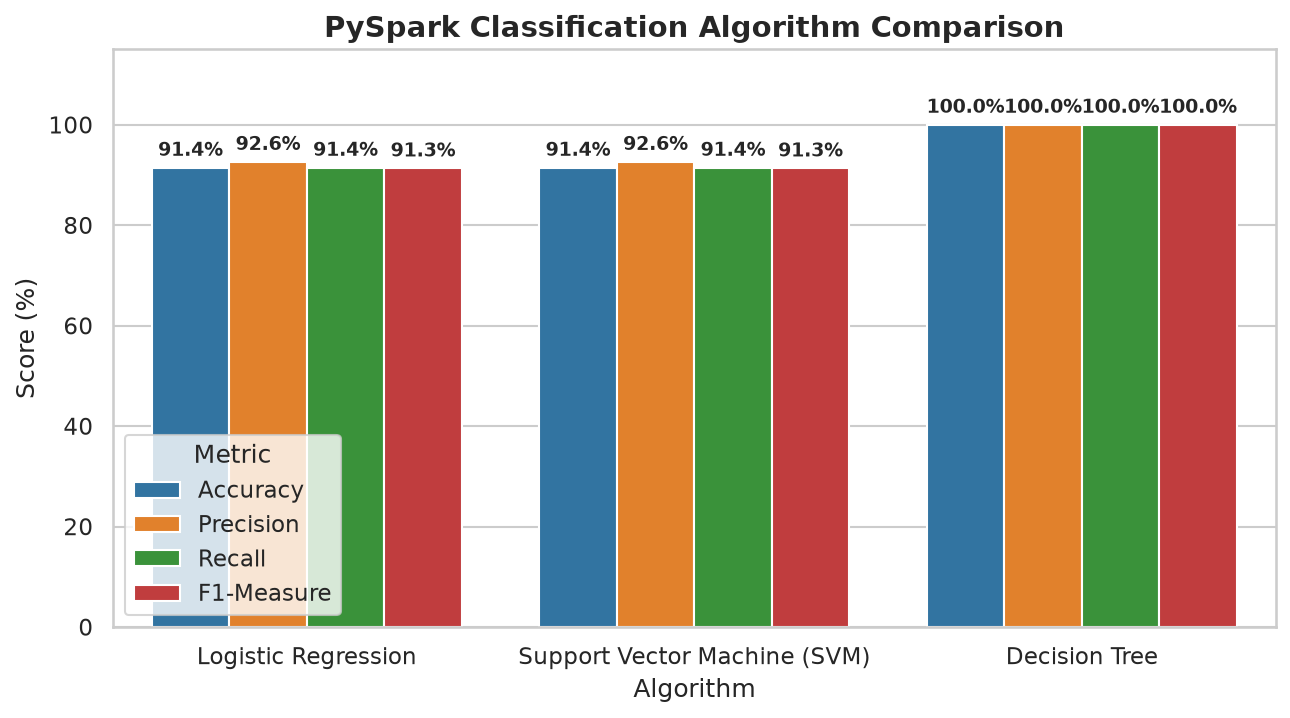

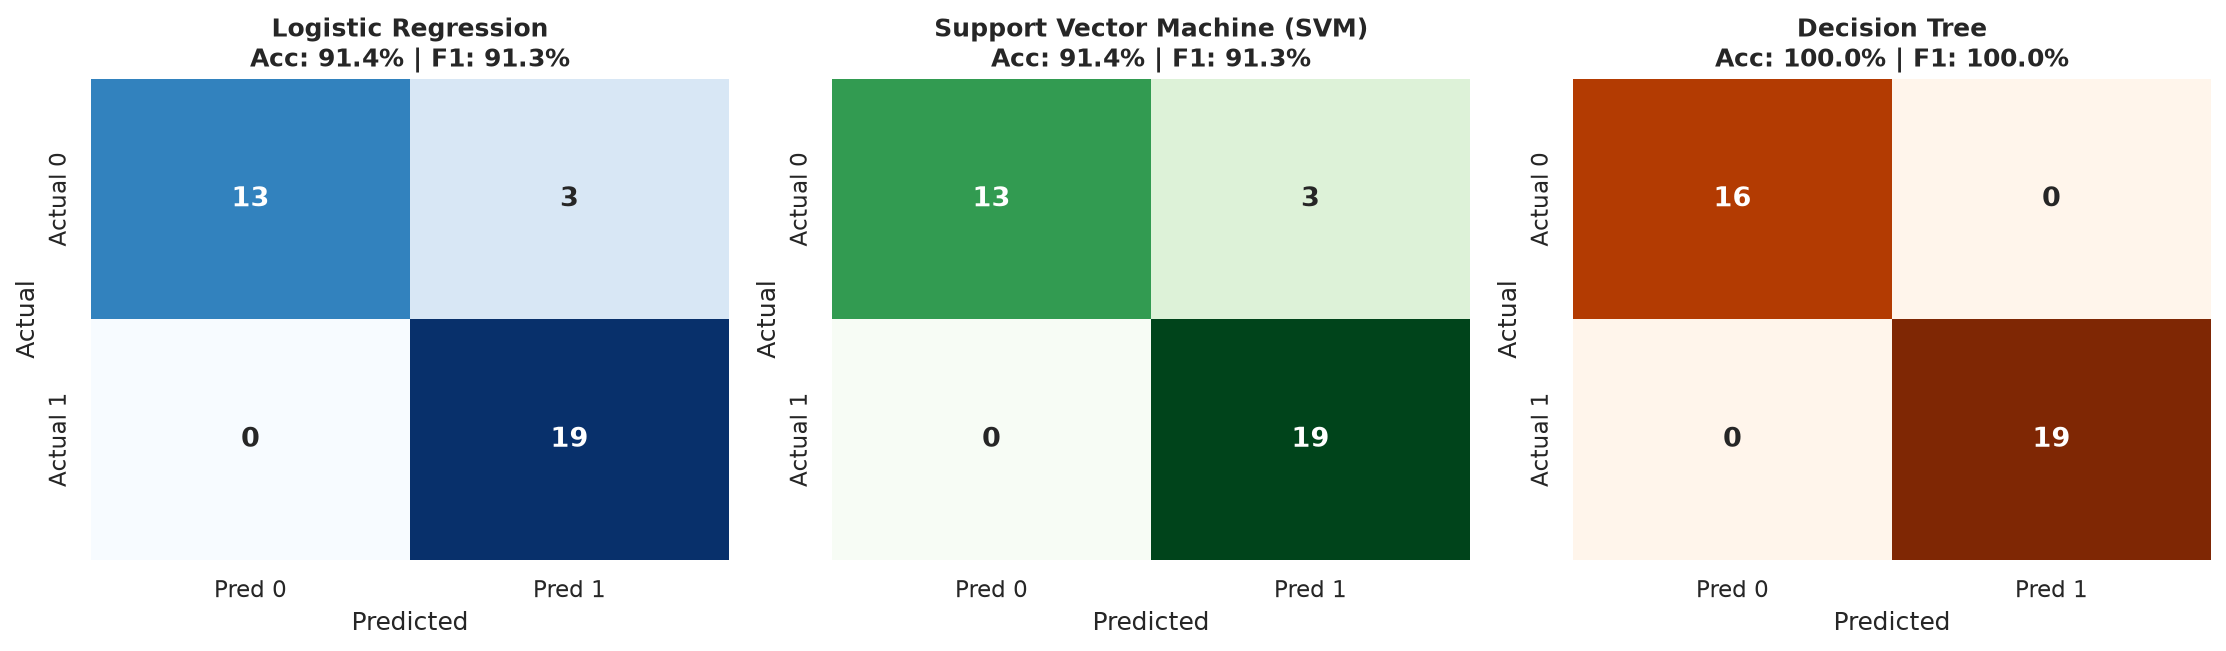

In [ ]:
plot_rows = []
for model, m in results.items():
    for metric_name, val in [('Accuracy', m['Accuracy']), ('Precision', m['Precision']), ('Recall', m['Recall']), ('F1-Measure', m['F1_Measure'])]:
        plot_rows.append({'Algorithm': model, 'Metric': metric_name, 'Score (%)': val * 100})

plot_df = pd.DataFrame(plot_rows)
plt.figure(figsize=(10, 5), dpi=150)
sns.set_theme(style="whitegrid")
ax = sns.barplot(data=plot_df, x="Algorithm", y="Score (%)", hue="Metric", palette=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"])
plt.title("PySpark Classification Algorithm Comparison", fontsize=14, fontweight='bold')
plt.ylim(0, 115)
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h + 1.5), ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=150)
cm_cmaps = ["Blues", "Greens", "Oranges"]
for i, (name, m) in enumerate(results.items()):
    sns.heatmap(m["Confusion_Matrix"], annot=True, fmt="d", cmap=cm_cmaps[i], cbar=False, ax=axes[i],
                annot_kws={"size": 13, "weight": "bold"},
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["Actual 0", "Actual 1"])
    axes[i].set_title(f"{name}\nAcc: {m['Accuracy']*100:.1f}% | F1: {m['F1_Measure']*100:.1f}%", fontweight='bold')
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")
plt.tight_layout()
plt.show()